In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Plotting style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

## 1. Load and Validate Optimised Parameters

Begin by loading the optimised parameters from the pickle file and validating that they produce outputs within the target range [0.4, 0.6] for all channels (r, g, b, y).


In [3]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """Fixed point equation for green neurons"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)
    return g_new

# Solve fixed point via Anderson Acceleration
def solve_fixed_point(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)
    return r, g, b, y


In [4]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [ ]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)

    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()

    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


## 2. Compute Hessian Eigenstructure

For each valid parameter set, we compute the Hessian matrix of the output function and extract its eigenvalues and eigenvectors. The eigenvectors corresponding to near-zero eigenvalues represent directions in parameter space where changes preserve the output.


Processing 982 samples...
  Sample 1/982...
  Sample 101/982...
  Sample 201/982...
  Sample 301/982...
  Sample 401/982...
  Sample 501/982...
  Sample 601/982...
  Sample 701/982...
  Sample 801/982...
  Sample 901/982...
Completed processing 982 samples


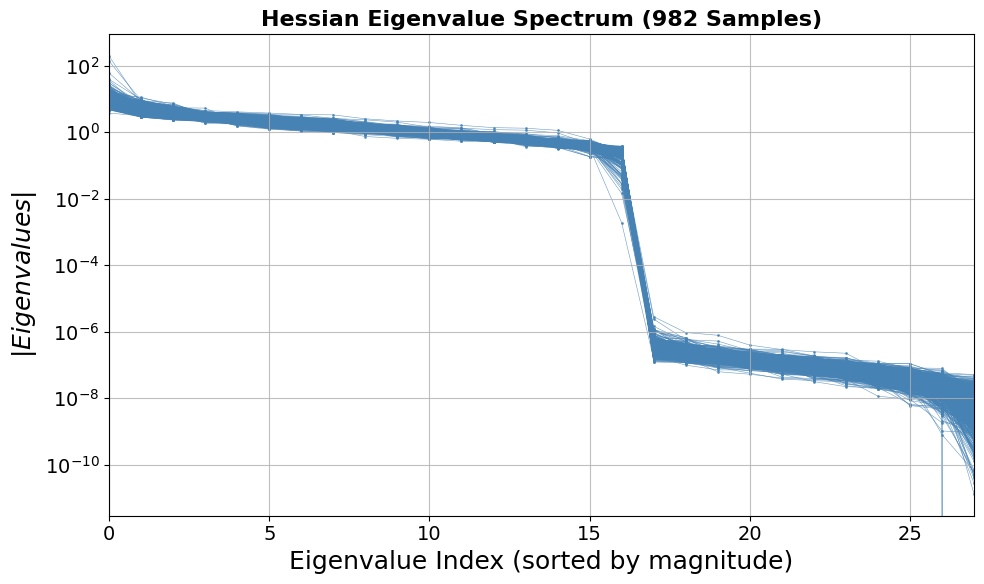

In [7]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Check Eigenvector-Gradient dot product

An important property: eigenvectors corresponding to zero eigenvalues should be perpendicular to the gradient. 



In [ ]:
# Compute dot products between eigenvectors and gradient for all samples
print(f"Computing eigenvector-gradient dot products for {n_samples} samples...")

# Pre-allocate arrays
dot_products_all = np.zeros((n_samples, n_params))
gradient_norms = np.zeros(n_samples)

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    grad_vec = np.array(grad(theta_star))

    # Normalize gradient vector
    grad_norm = np.linalg.norm(grad_vec)
    gradient_norms[i] = grad_norm

    if grad_norm > 1e-10:  # Avoid division by zero
        grad_vec_normalized = grad_vec / grad_norm
    else:
        grad_vec_normalized = grad_vec

    # Get eigenvectors for this sample (each column is an eigenvector)
    eigenvectors_i = all_eigenvectors[i]  # Shape: (n_params, n_params)

    # Normalize each eigenvector to unit length
    eigenvector_norms = np.linalg.norm(eigenvectors_i, axis=0, keepdims=True)
    # Avoid division by zero
    eigenvector_norms = np.where(eigenvector_norms > 1e-10, eigenvector_norms, 1.0)
    eigenvectors_normalized = eigenvectors_i / eigenvector_norms

    # Compute dot product of each normalized eigenvector with normalized gradient
    dot_products_all[i] = eigenvectors_normalized.T @ grad_vec_normalized

print(f"Completed computing dot products")

# Create pandas DataFrame for analysis
dot_products_df = pd.DataFrame(
    dot_products_all,
    columns=[f"Eigenvector_{i}" for i in range(n_params)]
)
dot_products_df['Sample'] = np.arange(n_samples)
dot_products_df['Gradient_Norm'] = gradient_norms

# Reshape to long format for easier analysis
dot_products_long = dot_products_df.melt(
    id_vars=['Sample', 'Gradient_Norm'],
    var_name='Eigenvector',
    value_name='Dot_Product'
)

# Extract eigenvector index from string
dot_products_long['Eigenvector_Index'] = (
    dot_products_long['Eigenvector']
    .str.extract(r'(\d+)')
    .astype(int)
)


Computing eigenvector-gradient dot products for 982 samples...
  Sample 1/982...
  Sample 101/982...
  Sample 201/982...
  Sample 301/982...
  Sample 401/982...
  Sample 501/982...
  Sample 601/982...
  Sample 701/982...
  Sample 801/982...
  Sample 901/982...
Completed computing dot products


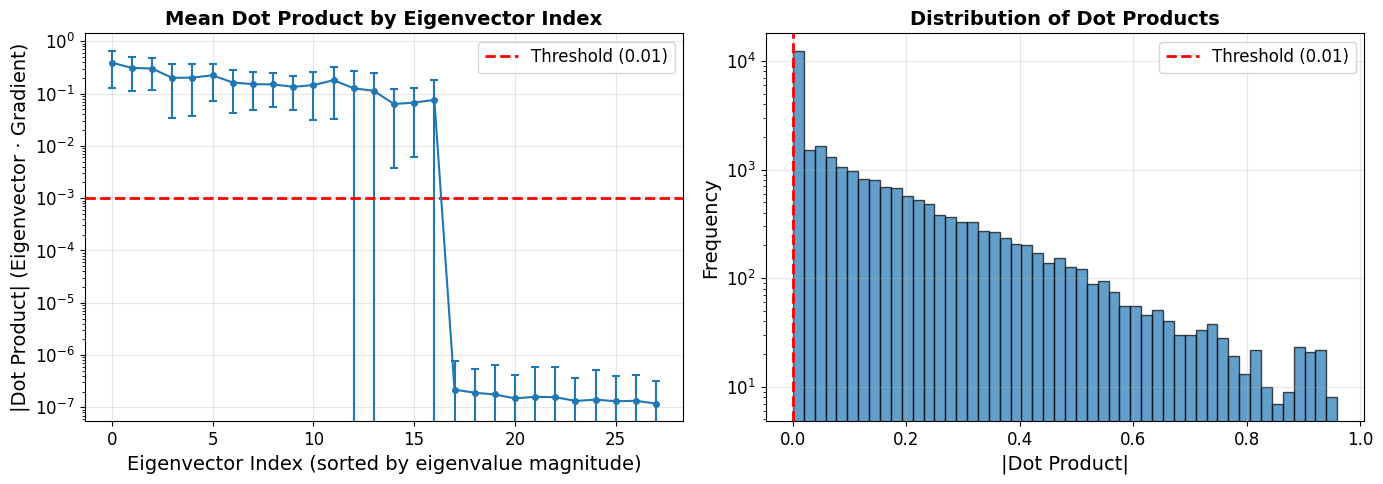


Eigenvectors with |dot product| < 0.001:
  Mean per sample: 11.09 out of 28
  Median per sample: 11.00
  Min per sample: 11
  Max per sample: 13


In [39]:
# Visualize dot products
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Dot products vs eigenvector index (mean across samples)
mean_dot_products = np.abs(dot_products_all).mean(axis=0)
std_dot_products = np.abs(dot_products_all).std(axis=0)

axes[0].errorbar(
    range(n_params), mean_dot_products, yerr=std_dot_products,
    fmt='o-', capsize=3, capthick=1.5, linewidth=1.5, markersize=4
)
axes[0].axhline(0.001, color='r', linestyle='--', linewidth=2, label='Threshold (0.01)')
axes[0].set_xlabel('Eigenvector Index (sorted by eigenvalue magnitude)', fontsize=14)
axes[0].set_ylabel('|Dot Product| (Eigenvector · Gradient)', fontsize=14)
axes[0].set_title('Mean Dot Product by Eigenvector Index', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')

# Plot 2: Distribution of dot products
axes[1].hist(np.abs(dot_products_all).flatten(), bins=50, edgecolor='black', alpha=0.7)
axes[1].axvline(0.001, color='r', linestyle='--', linewidth=2, label='Threshold (0.01)')
axes[1].set_xlabel('|Dot Product|', fontsize=14)
axes[1].set_ylabel('Frequency', fontsize=14)
axes[1].set_title('Distribution of Dot Products', fontsize=14, fontweight='bold')
axes[1].set_yscale('log')
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Count how many eigenvectors are approximately perpendicular (|dot| < 0.01)
perpendicular_threshold = 0.001
perpendicular_mask = np.abs(dot_products_all) < perpendicular_threshold
n_perpendicular = perpendicular_mask.sum(axis=1)  # Per sample

print(f"\nEigenvectors with |dot product| < {perpendicular_threshold}:")
print(f"  Mean per sample: {n_perpendicular.mean():.2f} out of {n_params}")
print(f"  Median per sample: {np.median(n_perpendicular):.2f}")
print(f"  Min per sample: {n_perpendicular.min()}")
print(f"  Max per sample: {n_perpendicular.max()}")


## 4. Eigenvector Structure



## Parameter changes preserving output


In [12]:
# Carefully stack and melt all_eigenvectors for long-format DataFrame
n_trials, n_dims, n_ev = all_eigenvectors.shape

# Create a DataFrame in long/melted format: each (trial, eigenvector_index, dimension) gets one row
df = (
    pd.DataFrame(
        all_eigenvectors.reshape(-1, n_ev),
        columns=[f"eig_{i}" for i in range(n_ev)]
    )
    .assign(
        trial=np.repeat(np.arange(n_trials), n_dims),
        dimension=np.tile(np.arange(n_dims), n_trials)
    )
    .melt(
        id_vars=["trial", "dimension"],
        var_name="eigenvector_index",
        value_name="value"
    )
)

# Convert string indices 'eig_#' to integers for easier filtering/plotting
df["eigenvector_index"] = df["eigenvector_index"].str.extract(r"(\d+)").astype(int)

# Now, check assertion for correct extraction
assert np.allclose(
    all_eigenvectors[0, :, 0],
    df[(df['trial'] == 0) & (df['eigenvector_index'] == 0)]
    .sort_values("dimension")["value"].values
)


In [13]:
all_eigenvectors[0, :, -1]

array([ 0.00000000e+00, -1.78257495e-01, -1.05239451e-07,  4.65661287e-09,
       -1.60795033e-01, -5.80106154e-02, -1.05671495e-01,  5.60179129e-02,
        1.04541451e-01,  3.31556499e-02, -3.91996980e-01, -3.43293965e-01,
       -2.58314401e-01, -8.01707879e-02, -6.87325075e-02, -4.68546636e-02,
       -1.04586788e-01, -2.37850830e-01,  2.42143869e-07,  7.82310963e-08,
       -4.58570749e-01,  3.54029536e-01,  1.82037260e-02, -3.75369161e-01,
       -6.02149591e-02,  6.09160736e-02,  5.64029850e-02,  7.87338987e-02])

In [14]:
df[(df['trial']==0)&(df['eigenvector_index']==27)]

,trial,dimension,eigenvector_index,value
742392,0,0,27,0.000000e+00
742393,0,1,27,-1.782575e-01
742394,0,2,27,-1.052395e-07
742395,0,3,27,4.656613e-09
742396,0,4,27,-1.607950e-01
742397,0,5,27,-5.801062e-02
742398,0,6,27,-1.056715e-01
742399,0,7,27,5.601791e-02
742400,0,8,27,1.045415e-01
742401,0,9,27,3.315565e-02


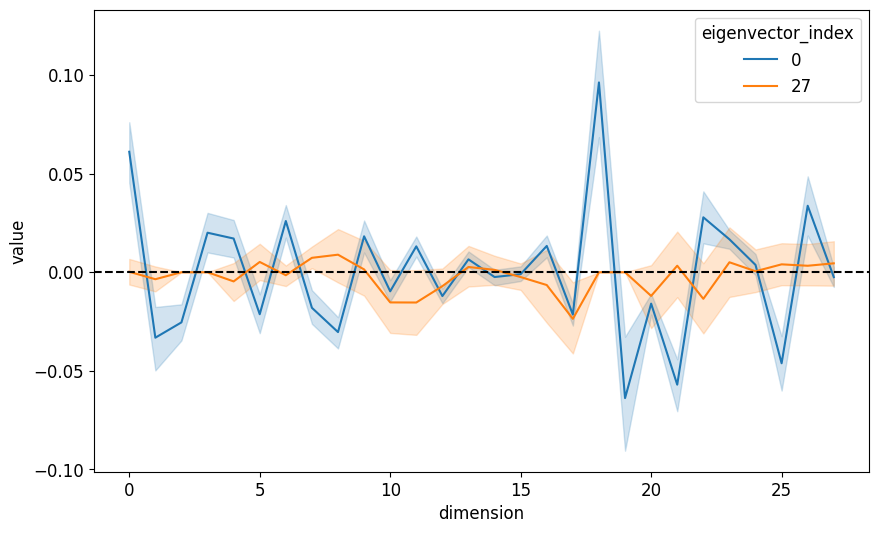

In [18]:
sns.lineplot(
    data=df[(df['eigenvector_index']==0)|(df['eigenvector_index']==27)],
    x='dimension',
    y='value',
    hue='eigenvector_index',
    palette='tab10',
    # errorbar='sd'
    )

plt.axhline(y=0, color='k', linestyle='--')

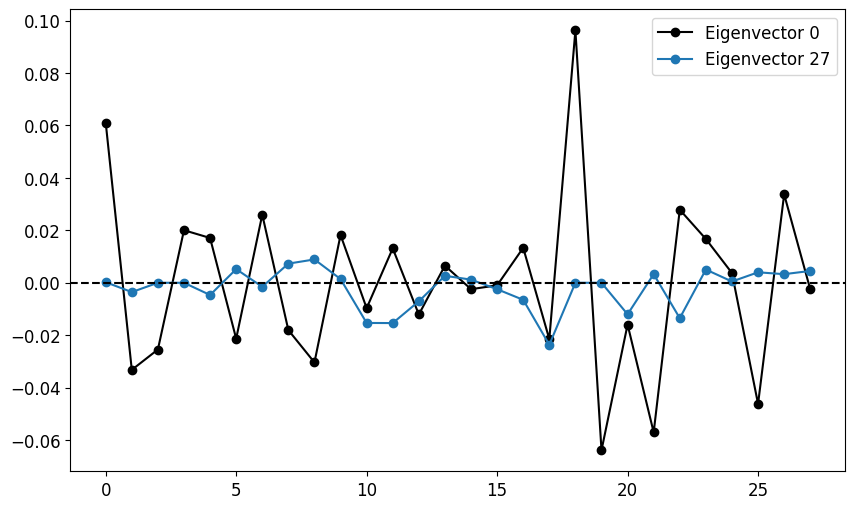

In [41]:
mean = np.mean(all_eigenvectors, axis=0)
std = np.std(all_eigenvectors, axis=0)

plt.plot(mean[:,0],'o-', c='k',label='Eigenvector 0')
plt.plot(mean[:,-1],'o-',label='Eigenvector 27')

plt.legend()
plt.axhline(y=0, color='k', linestyle='--')
plt.show()

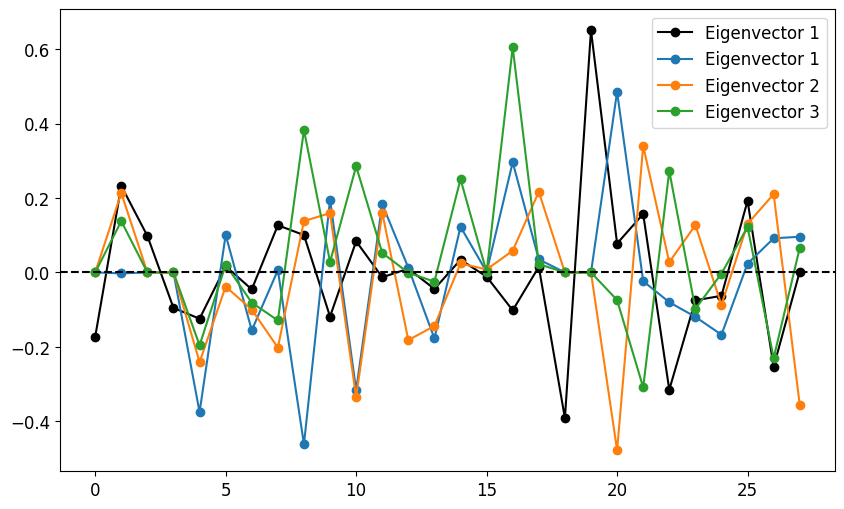

In [ ]:

i=50
#plot the eigenvector
plt.plot(all_eigenvectors[i][:,0],'o-', c='k',label='Eigenvector 1')
plt.plot(all_eigenvectors[i][:,-1],'o-',label='Eigenvector 1')
plt.plot(all_eigenvectors[i][:,-2],'o-',label='Eigenvector 2')
plt.plot(all_eigenvectors[i][:,-3],'o-',label='Eigenvector 3')
plt.legend()
plt.axhline(y=0, color='k', linestyle='--')
plt.show()


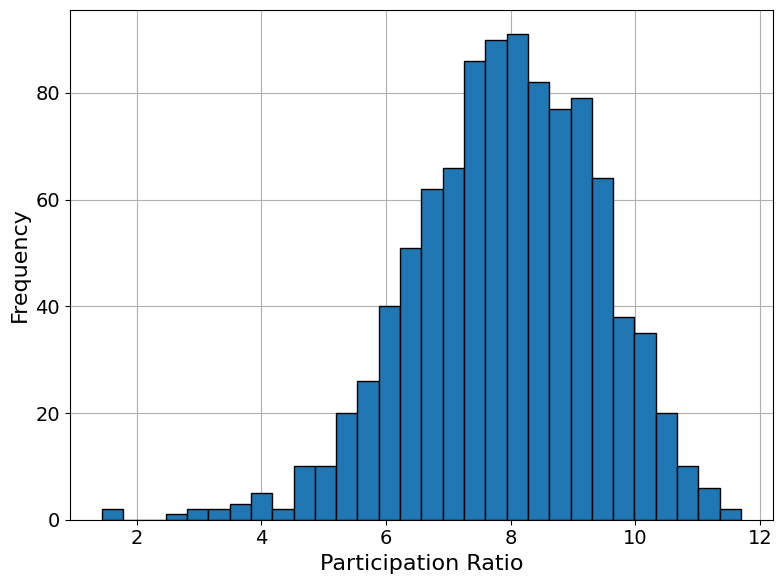

In [ ]:
## participation ratio
## plot histogram of participation ratio

'''
participation_ratios = []
for i in range(theta_opt.shape[0]):
    H = hessian(theta_opt[i, :])
    H = jnp.squeeze(H)
    eigenvalues_H = jnp.linalg.eigh(H)[0]
    ppr = (jnp.sum(jnp.abs(eigenvalues_H)) ** 2) / jnp.sum(eigenvalues_H ** 2)
    participation_ratios.append(ppr)

participation_ratios = np.array(participation_ratios)

plt.figure(figsize=(8, 6))
plt.grid(True, zorder=0)
plt.hist(participation_ratios, bins=30, edgecolor='black', zorder=2)
plt.xlabel('Participation Ratio', fontsize=16)
plt.ylabel('Frequency', fontsize=16)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.savefig('Figures/participation_ratio.eps')
plt.show()
'''

In [21]:
theta_picked = theta_opt[0]
e_vector_1 = all_eigenvectors[0][:, 0]
e_vector_2 = all_eigenvectors[0][:, 8]
e_vector_3 = all_eigenvectors[0][:, 14]
e_vector_4 = all_eigenvectors[0][:, 18]
e_vector_5 = all_eigenvectors[0][:, 27]

#normalise the eigenvectors
de_magnitude = 0.01*jnp.linalg.norm(theta_picked)
print(de_magnitude)
e_vector_1 = e_vector_1 / jnp.linalg.norm(e_vector_1) * de_magnitude
e_vector_2 = e_vector_2 / jnp.linalg.norm(e_vector_2) * de_magnitude
e_vector_3 = e_vector_3 / jnp.linalg.norm(e_vector_3) * de_magnitude
e_vector_4 = e_vector_4 / jnp.linalg.norm(e_vector_4) * de_magnitude
e_vector_5 = e_vector_5 / jnp.linalg.norm(e_vector_5) * de_magnitude

r_0, g_0, b_0, y_0 = mitral_output(theta_picked, x, m)
r_1, g_1, b_1, y_1 = mitral_output(theta_picked + e_vector_1, x, m)
r_2, g_2, b_2, y_2 = mitral_output(theta_picked + e_vector_2, x, m)
r_3, g_3, b_3, y_3 = mitral_output(theta_picked + e_vector_3, x, m)
r_4, g_4, b_4, y_4 = mitral_output(theta_picked + e_vector_4, x, m)
r_5, g_5, b_5, y_5 = mitral_output(theta_picked + e_vector_5, x, m)

import pandas as pd

# Convert to numpy arrays if not already
r_0, g_0, b_0, y_0 = np.array(r_0), np.array(g_0), np.array(b_0), np.array(y_0)
r_1, g_1, b_1, y_1 = np.array(r_1), np.array(g_1), np.array(b_1), np.array(y_1)
r_2, g_2, b_2, y_2 = np.array(r_2), np.array(g_2), np.array(b_2), np.array(y_2)
r_3, g_3, b_3, y_3 = np.array(r_3), np.array(g_3), np.array(b_3), np.array(y_3)
r_4, g_4, b_4, y_4 = np.array(r_4), np.array(g_4), np.array(b_4), np.array(y_4)
r_5, g_5, b_5, y_5 = np.array(r_5), np.array(g_5), np.array(b_5), np.array(y_5)

# Create a dictionary for the dataframe
data = {
    "Original": [r_0, g_0, b_0, y_0],
    "Eigenvec 1": [r_1, g_1, b_1, y_1],
    "Eigenvec 2": [r_2, g_2, b_2, y_2],
    "Eigenvec 3": [r_3, g_3, b_3, y_3],
    "Eigenvec 4": [r_4, g_4, b_4, y_4],
    "Eigenvec 5": [r_5, g_5, b_5, y_5],
}

channels = ["r", "g", "b", "y"]
df = pd.DataFrame(data, index=channels)

print("="*60)
print("Output Values Comparison (as pandas DataFrame)")
print("="*60)
print(df)
print("="*60)


0.036905743
Output Values Comparison (as pandas DataFrame)
                  Original                Eigenvec 1  \
r  [0.49999994, 0.5000001]   [0.46893412, 0.5470972]   
g   [0.5000001, 0.5000001]   [0.45860484, 0.5555982]   
b  [0.5000001, 0.49999994]  [0.48096654, 0.51665384]   
y               [0.5, 0.5]   [0.45341438, 0.5758466]   

                 Eigenvec 2                Eigenvec 3  \
r  [0.49302977, 0.49973947]  [0.49987262, 0.49956268]   
g  [0.50780004, 0.50102377]   [0.5013382, 0.50132024]   
b   [0.5281036, 0.49631852]  [0.50031483, 0.50533813]   
y    [0.511127, 0.49946475]    [0.5007955, 0.5011713]   

                Eigenvec 4               Eigenvec 5  
r               [0.5, 0.5]               [0.5, 0.5]  
g               [0.5, 0.5]               [0.5, 0.5]  
b  [0.5000001, 0.49999994]  [0.5000001, 0.49999994]  
y               [0.5, 0.5]        [0.5, 0.49999994]  


## 5. Quantifying Output Sensitivity to Parameter Changes

Perturb parameters along eigenvector directions and measure the resulting change in output. To enable fair comparison across eigenvectors, use a "normalised sensitivity metric":

Sensitivity = (Relative change in output) / (Relative change in parameters)

Where:
- Relative change in output: ||Δy|| / ||y₀|| (magnitude of output change normalised by original output magnitude)
- Relative change in parameters: ||Δθ|| / ||θ₀|| (magnitude of parameter change normalised by original parameter magnitude)

(dimensionless - "For a 1% change in parameters along this eigenvector direction, what percentage change do we see in the output?")

In [ ]:
# Select a sample parameter set and specific eigenvectors to test
sample_idx = 0
theta_0 = jnp.array(theta_opt[sample_idx])

# Select eigenvectors corresponding to different eigenvalue magnitudes
# (largest, medium, and smallest eigenvalues)
eigenvec_indices = [0, 8, 14, 20, 27]  # Different eigenvalue ranks
eigenvec_labels = [f"Eigenvec {i+1}" for i in range(len(eigenvec_indices))]

# Set perturbation magnitude: 1% of parameter vector norm
perturbation_fraction = 0.01
delta_theta_magnitude = perturbation_fraction * jnp.linalg.norm(theta_0)

print(f"Original parameter vector norm: ||θ₀|| = {jnp.linalg.norm(theta_0):.6f}")
print(f"Perturbation magnitude: ||Δθ|| = {delta_theta_magnitude:.6f} ({perturbation_fraction*100}% of ||θ₀||)")
print()

# Compute original output
r_0, g_0, b_0, y_0 = mitral_output(theta_0, x, m)
y_0 = np.array(y_0)
y_0_norm = np.linalg.norm(y_0)
theta_0_norm = jnp.linalg.norm(theta_0)

print(f"Original output y₀: {y_0}")
print(f"Original output norm: ||y₀|| = {y_0_norm:.6f}")
print()

# Store results
sensitivity_results = {
    'Eigenvector': [],
    'Eigenvalue_Rank': [],
    'Eigenvalue': [],
    '||Δθ||/||θ₀||': [],
    '||Δy||/||y₀||': [],
    'Sensitivity': [],
    'y_perturbed': []
}

# Test each eigenvector
for i, eig_idx in enumerate(eigenvec_indices):
    # Get eigenvector and normalise to perturbation magnitude
    eigenvec = all_eigenvectors[sample_idx][:, eig_idx]
    eigenvec_normalized = eigenvec / jnp.linalg.norm(eigenvec) * delta_theta_magnitude

    # Perturb parameters
    theta_perturbed = theta_0 + eigenvec_normalized

    # Compute perturbed output
    r_p, g_p, b_p, y_p = mitral_output(theta_perturbed, x, m)
    y_p = np.array(y_p)

    # Compute changes
    delta_y = y_p - y_0
    delta_theta = theta_perturbed - theta_0

    # Compute norms
    delta_y_norm = np.linalg.norm(delta_y)
    delta_theta_norm = jnp.linalg.norm(delta_theta)

    # Compute relative changes
    rel_change_y = delta_y_norm / y_0_norm
    rel_change_theta = delta_theta_norm / theta_0_norm

    # Compute normalised sensitivity:
    sensitivity = rel_change_y / rel_change_theta if rel_change_theta > 0 else np.nan

    # Get corresponding eigenvalue
    eig_val = all_eigenvalues[sample_idx, eig_idx]

    # Store results
    sensitivity_results['Eigenvector'].append(eigenvec_labels[i])
    sensitivity_results['Eigenvalue'].append(eig_val)
    sensitivity_results['||Δθ||/||θ₀||'].append(rel_change_theta)
    sensitivity_results['||Δy||/||y₀||'].append(rel_change_y)
    sensitivity_results['Sensitivity'].append(sensitivity)
    sensitivity_results['y_perturbed'].append(y_p)

    print(f"{eigenvec_labels[i]} (rank {eig_idx}):")
    print(f"  Eigenvalue: {eig_val:.6e}")
    print(f"  ||Δθ||/||θ₀||: {rel_change_theta:.6f}")
    print(f"  ||Δy||/||y₀||: {rel_change_y:.6f}")
    print(f"  Sensitivity: {sensitivity:.6f}")
    print(f"  y_perturbed: {y_p}")
    print()


Original parameter vector norm: ||θ₀|| = 3.690574
Perturbation magnitude: ||Δθ|| = 0.036906 (1.0% of ||θ₀||)

Original output y₀: [0.5 0.5]
Original output norm: ||y₀|| = 0.707107

Eigenvec 1 (rank 0):
  Eigenvalue: 7.546333e+00
  ||Δθ||/||θ₀||: 0.010000
  ||Δy||/||y₀||: 0.125880
  Sensitivity: 12.588023
  y_perturbed: [0.45341438 0.5758466 ]

Eigenvec 2 (rank 8):
  Eigenvalue: 1.233921e+00
  ||Δθ||/||θ₀||: 0.010000
  ||Δy||/||y₀||: 0.015754
  Sensitivity: 1.575415
  y_perturbed: [0.511127   0.49946475]

Eigenvec 3 (rank 14):
  Eigenvalue: 4.042388e-01
  ||Δθ||/||θ₀||: 0.010000
  ||Δy||/||y₀||: 0.002002
  Sensitivity: 0.200236
  y_perturbed: [0.5007955 0.5011713]

Eigenvec 4 (rank 20):
  Eigenvalue: 1.174008e-07
  ||Δθ||/||θ₀||: 0.010000
  ||Δy||/||y₀||: 0.000000
  Sensitivity: 0.000017
  y_perturbed: [0.5000001 0.5      ]

Eigenvec 5 (rank 27):
  Eigenvalue: 1.243254e-08
  ||Δθ||/||θ₀||: 0.010000
  ||Δy||/||y₀||: 0.000000
  Sensitivity: 0.000008
  y_perturbed: [0.5        0.49999994]


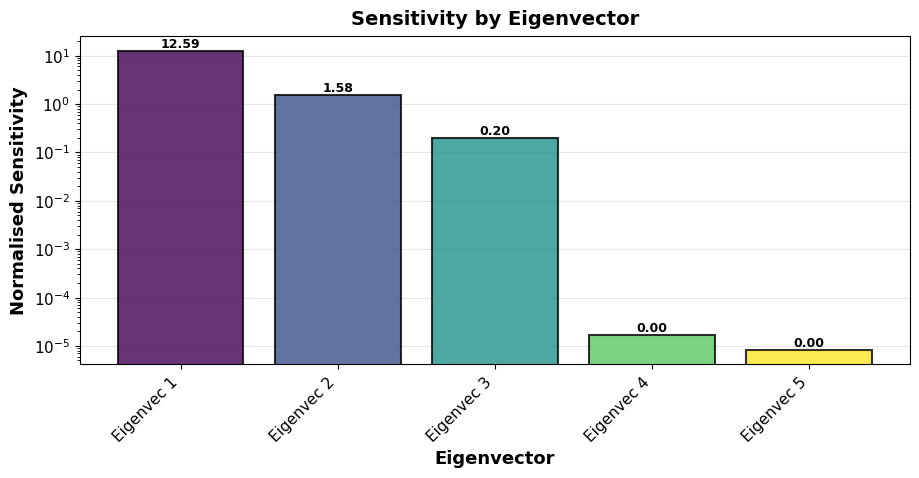


Interpretation:
• Low sensitivity (< 1): Output changes less than parameters → output-preserving direction
• High sensitivity (> 1): Output changes more than parameters → output-changing direction
• Sensitivity ≈ 1: Output changes proportionally to parameters


In [51]:
# Visualise sensitivity by eigenvector
n_eigenvecs = len(sensitivity_results['Eigenvector'])
sensitivities = sensitivity_results['Sensitivity']
eigenvec_labels = sensitivity_results['Eigenvector']

fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))
fig.subplots_adjust(left=0.12, right=0.95, top=0.88, bottom=0.15)

# Bar chart of sensitivities
colors = plt.cm.viridis(np.linspace(0, 1, n_eigenvecs))
bars = ax.bar(range(n_eigenvecs), sensitivities,
              color=colors, edgecolor='black', linewidth=1.5, alpha=0.8, zorder=2)
ax.set_xlabel('Eigenvector', fontsize=13, fontweight='bold')
ax.set_ylabel('Normalised Sensitivity', fontsize=13, fontweight='bold')
ax.set_title('Sensitivity by Eigenvector', fontsize=14, fontweight='bold', pad=8)
ax.set_xticks(range(n_eigenvecs))
ax.set_xticklabels(eigenvec_labels, rotation=45, ha='right', fontsize=10)
ax.set_yscale('log')
ax.grid(True, alpha=0.3, axis='y', zorder=0)
ax.tick_params(labelsize=11)

# Add value labels on bars
for i, sensitivity_val in enumerate(sensitivities):
    # Handle zero or very small values for log scale
    if sensitivity_val > 0:
        ax.text(i, sensitivity_val, f"{sensitivity_val:.2f}",
                ha='center', va='bottom', fontsize=9, fontweight='bold', zorder=4)
    else:
        # For zero sensitivity, place label at a small value above the bar
        ax.text(i, 1e-5, "0.00",
                ha='center', va='bottom', fontsize=9, fontweight='bold', zorder=4, color='gray')

plt.show()

print("\n" + "="*70)
print("Interpretation:")
print("="*70)
print("• Low sensitivity (< 1): Output changes less than parameters → output-preserving direction")
print("• High sensitivity (> 1): Output changes more than parameters → output-changing direction")
print("• Sensitivity ≈ 1: Output changes proportionally to parameters")
print("="*70)

 Dot product between eigen vectors
 - if 0, then different directions
 - if large (near 1), strongly related

In [ ]:
eigenvalues_sample = all_eigenvalues[sample_idx]
eigenvectors_sample = all_eigenvectors[sample_idx]  # Shape: (n_params, n_params)

eigenvalue_threshold = 1e-5
low_eig_idx = np.where(eigenvalues_sample < eigenvalue_threshold)[0]
print(low_eig_idx)

[17 18 19 20 21 22 23 24 25 26 27]


Sample 0: Found 11 eigenvectors with eigenvalue < 1e-05


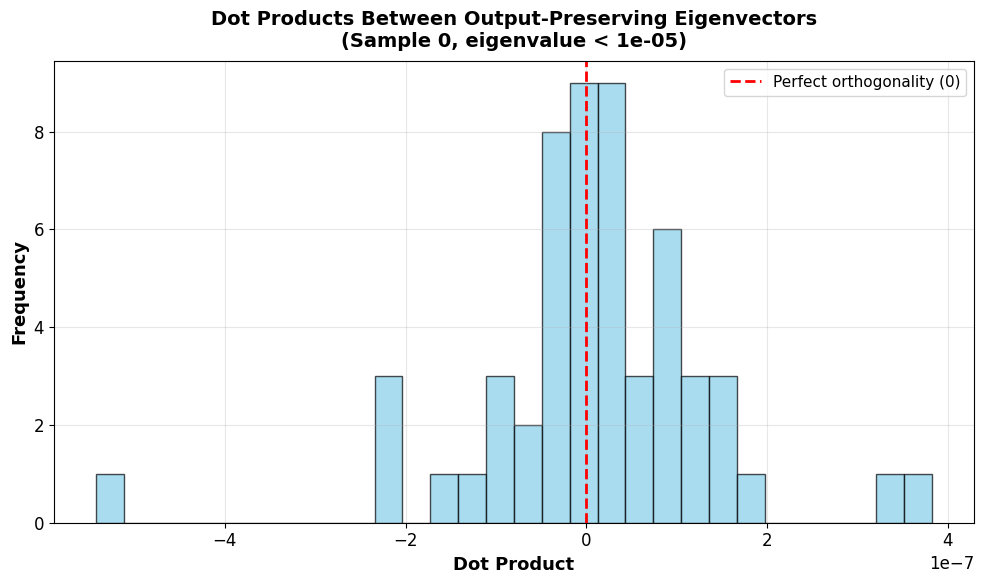

In [65]:
# dot product of between eigenvectors
# histogram of dot product of between eigenvectors
# for all eigenvectors that have eigenvalue < 1e-5



sample_idx = 0  # Use first sample 0, or None to analyze all samples
eigenvalue_threshold = 1e-5  # Threshold for "near-zero" eigenvalues

if sample_idx is not None:
    # Analyze single sample
    eigenvalues_sample = all_eigenvalues[sample_idx]
    eigenvectors_sample = all_eigenvectors[sample_idx]  # Shape: (n_params, n_params)

    # Find eigenvectors with eigenvalues below threshold
    low_eig_idx = np.where(eigenvalues_sample < eigenvalue_threshold)[0]

    if len(low_eig_idx) > 0:
        # Extract eigenvectors (each column is an eigenvector)
        eigenvecs_sub = eigenvectors_sample[:, low_eig_idx]  # Shape: (n_params, n_low_eig)

        # Normalise eigenvectors to unit length
        eigenvec_norms = np.linalg.norm(eigenvecs_sub, axis=0, keepdims=True)
        eigenvec_norms = np.where(eigenvec_norms > 1e-10, eigenvec_norms, 1.0)
        eigenvecs_normalized = eigenvecs_sub / eigenvec_norms

        # Compute dot products between all pairs (upper triangular, excluding diagonal)
        n_low_eig = eigenvecs_normalized.shape[1]
        dot_products = []
        for i in range(n_low_eig):
            for j in range(i+1, n_low_eig):
                dot = np.dot(eigenvecs_normalized[:, i], eigenvecs_normalized[:, j])
                dot_products.append(dot)

        dot_products = np.array(dot_products)

        print(f"Sample {sample_idx}: Found {n_low_eig} eigenvectors with eigenvalue < {eigenvalue_threshold}")


        # Plot histogram
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.hist(dot_products, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
        ax.axvline(0, color='r', linestyle='--', linewidth=2, label='Perfect orthogonality (0)')
        ax.set_xlabel('Dot Product', fontsize=13, fontweight='bold')
        ax.set_ylabel('Frequency', fontsize=13, fontweight='bold')
        ax.set_title(f'Dot Products Between Output-Preserving Eigenvectors\n(Sample {sample_idx}, eigenvalue < {eigenvalue_threshold:.0e})',
                    fontsize=14, fontweight='bold', pad=10)
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

else:
    # Analyse across all samples (aggregate statistics)
    print(f"Analysing across all {n_samples} samples...")
    all_dot_products = []

    for s_idx in range(n_samples):
        eigenvalues_s = all_eigenvalues[s_idx]
        eigenvectors_s = all_eigenvectors[s_idx]

        low_eig_idx = np.where(eigenvalues_s < eigenvalue_threshold)[0]

        if len(low_eig_idx) > 1:
            eigenvecs_sub = eigenvectors_s[:, low_eig_idx]
            eigenvec_norms = np.linalg.norm(eigenvecs_sub, axis=0, keepdims=True)
            eigenvec_norms = np.where(eigenvec_norms > 1e-10, eigenvec_norms, 1.0)
            eigenvecs_normalized = eigenvecs_sub / eigenvec_norms

            n_low_eig = eigenvecs_normalized.shape[1]
            for i in range(n_low_eig):
                for j in range(i+1, n_low_eig):
                    dot = np.dot(eigenvecs_normalized[:, i], eigenvecs_normalized[:, j])
                    all_dot_products.append(dot)

    if len(all_dot_products) > 0:
        all_dot_products = np.array(all_dot_products)
        print(f"Total eigenvector pairs analysed: {len(all_dot_products)}")


        # Plot histogram
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.hist(all_dot_products, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
        ax.axvline(0, color='r', linestyle='--', linewidth=2, label='Perfect orthogonality (0)')
        ax.set_xlabel('Dot Product', fontsize=13, fontweight='bold')
        ax.set_ylabel('Frequency', fontsize=13, fontweight='bold')
        ax.set_title(f'Dot Products Between Output-Preserving Eigenvectors\n(All {n_samples} samples, eigenvalue < {eigenvalue_threshold:.0e})',
                    fontsize=14, fontweight='bold', pad=10)
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No eigenvector pairs found with eigenvalue < {eigenvalue_threshold}")

Matrix shape: (11, 11)
Min value: -0.000001
Max value: 1.000000
Mean absolute off-diagonal: 0.000000



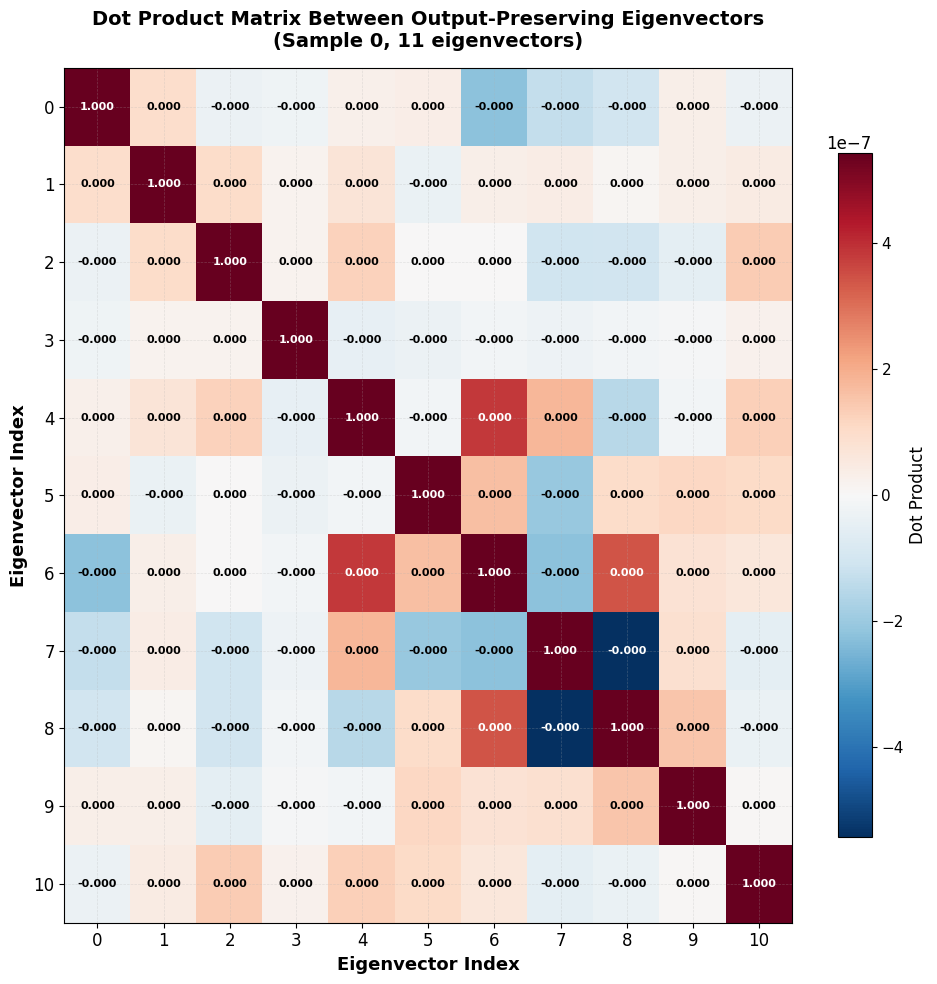

Interpretation:
• Diagonal values = 1 (eigenvector dot product with itself)
• Off-diagonal values near 0 = orthogonal (independent) eigenvectors
• Off-diagonal values near ±1 = parallel (dependent) eigenvectors


In [ ]:
# Create a matrix heatmap of dot products between eigenvectors
# Recompute dot products directly into a matrix for clarity
dot_product_matrix = np.zeros((n_low_eig, n_low_eig))

# Compute dot products directly and fill matrix
for i in range(n_low_eig):
    for j in range(n_low_eig):
        if i == j:
            dot_product_matrix[i, j] = 1.0  # Diagonal: eigenvector with itself
        else:
            # Compute dot product between normalized eigenvectors
            dot_product_matrix[i, j] = np.dot(eigenvecs_normalized[:, i], eigenvecs_normalized[:, j])

# Print some statistics for debugging
print(f"Matrix shape: {dot_product_matrix.shape}")
print(f"Min value: {dot_product_matrix.min():.6f}")
print(f"Max value: {dot_product_matrix.max():.6f}")
off_diagonal = dot_product_matrix.copy()
np.fill_diagonal(off_diagonal, np.nan)
print(f"Mean absolute off-diagonal: {np.nanmean(np.abs(off_diagonal)):.6f}")
print()

# Find the range for better colormap scaling (exclude diagonal)
off_diagonal = dot_product_matrix.copy()
np.fill_diagonal(off_diagonal, np.nan)
vmax = np.nanmax(np.abs(off_diagonal))
vmin = -vmax if vmax > 0 else -1

# Plot as heatmap
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(dot_product_matrix, cmap='RdBu_r', interpolation='nearest',
               vmin=vmin, vmax=vmax, aspect='auto')
cbar = plt.colorbar(im, ax=ax, label='Dot Product', shrink=0.8)
cbar.ax.tick_params(labelsize=11)

# Add text annotations for better readability (if matrix is not too large)
if n_low_eig <= 20:
    for i in range(n_low_eig):
        for j in range(n_low_eig):
            val = dot_product_matrix[i, j]
            text_color = "white" if abs(val) > abs(vmax) * 0.5 else "black"
            ax.text(j, i, f'{val:.3f}',
                  ha="center", va="center", color=text_color,
                  fontsize=8, fontweight='bold')

ax.set_title(f'Dot Product Matrix Between Output-Preserving Eigenvectors\n(Sample {sample_idx}, {n_low_eig} eigenvectors)',
            fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Eigenvector Index', fontsize=13, fontweight='bold')
ax.set_ylabel('Eigenvector Index', fontsize=13, fontweight='bold')
ax.set_xticks(range(n_low_eig))
ax.set_yticks(range(n_low_eig))
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

plt.tight_layout()
plt.show()

print("Interpretation:")
print("• Diagonal values = 1 (eigenvector dot product with itself)")
print("• Off-diagonal values near 0 = orthogonal (independent) eigenvectors")
print("• Off-diagonal values near ±1 = parallel (dependent) eigenvectors")